In [1]:
# q3 - regressao logistica bayesiana
# Levi Félix Barbosa - 579420

import numpy as np
import matplotlib.pyplot as plt

dados = np.loadtxt("logistic_regression_data.csv", delimiter=",")
x, y = dados[:, :2], dados[:, 2]
N = len(y)
print(N, "pontos,", int(y.sum()), "da classe 1")

100 pontos, 50 da classe 1


In [2]:
# modelo: p(y=1|x, w) = sigma(w^T x), com x_i = [1, x_i1, x_i2]
# priori: p(w) = N(w|m0, S0), com m0 = 0 e S0 = I
def sigmoide(z):
    return 1 / (1 + np.exp(-z))

def add_bias(x):
    return np.c_[np.ones(len(x)), x]

X = add_bias(x)
D = X.shape[1]
m0 = np.zeros(D)
S0 = np.eye(D)
S0_inv = np.linalg.inv(S0)

In [3]:
# solucao MAP via IRLS:
# w_t = w_{t-1} + A^-1 [X^T (y - sigma(X w_{t-1})) - S0^-1 (w_{t-1} - m0)]
# A = X^T R X + S0^-1, R_ii = sigma(w^T x_i)(1 - sigma(w^T x_i))
w = np.zeros(D)
for t in range(1, 51):
    s = sigmoide(X @ w)
    R = np.diag(s * (1 - s))
    A = X.T @ R @ X + S0_inv
    passo = np.linalg.solve(A, X.T @ (y - s) - S0_inv @ (w - m0))
    w = w + passo
    if np.linalg.norm(passo) < 1e-8:
        break

w_map = w
print("convergiu em", t, "iteracoes")
print("w_MAP:", w_map)

convergiu em 8 iteracoes
w_MAP: [ 0.51531419 -2.81281332  1.44860203]


In [4]:
# aproximacao de Laplace: p(w|D) ~ N(w|w_MAP, H^-1), H = X^T R X + S0^-1 no w_MAP
s = sigmoide(X @ w_map)
H = X.T @ np.diag(s * (1 - s)) @ X + S0_inv
H_inv = np.linalg.inv(H)
print("covariancia a posteriori (H^-1):")
print(H_inv)

acc = np.mean((s >= 0.5) == y)
print("acuracia no treino:", acc)

covariancia a posteriori (H^-1):
[[ 0.16799293 -0.00697522  0.04936449]
 [-0.00697522  0.28886403  0.03014287]
 [ 0.04936449  0.03014287  0.32381187]]
acuracia no treino: 0.98


In [5]:
# preditiva via aproximacao probit:
# p(y*=1|x*) ~ sigma((1 + pi*sigma_a2/8)^(-1/2) * mu_a)
# mu_a = w_MAP^T x*, sigma_a2 = x*^T H^-1 x*
def preditiva(xs):
    Xs = add_bias(xs)
    mu_a = Xs @ w_map
    sigma_a2 = np.sum(Xs @ H_inv * Xs, axis=1)
    return sigmoide(mu_a / np.sqrt(1 + np.pi * sigma_a2 / 8))

g1 = np.linspace(x[:, 0].min() - 1, x[:, 0].max() + 1, 200)
g2 = np.linspace(x[:, 1].min() - 1, x[:, 1].max() + 1, 200)
G1, G2 = np.meshgrid(g1, g2)
p = preditiva(np.c_[G1.ravel(), G2.ravel()]).reshape(G1.shape)

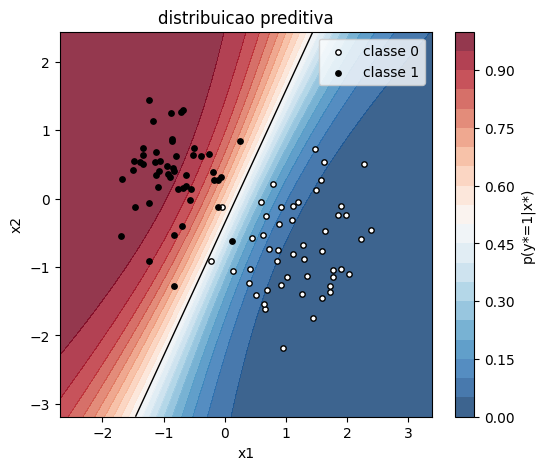

In [6]:
plt.figure(figsize=(6, 5))
plt.contourf(G1, G2, p, levels=20, cmap="RdBu_r", alpha=0.8)
plt.colorbar(label="p(y*=1|x*)")
plt.contour(G1, G2, p, levels=[0.5], colors="k", linewidths=1)
plt.scatter(x[y == 0, 0], x[y == 0, 1], s=15, c="white", edgecolors="k", label="classe 0")
plt.scatter(x[y == 1, 0], x[y == 1, 1], s=15, c="k", label="classe 1")
plt.title("distribuicao preditiva")
plt.xlabel("x1")
plt.ylabel("x2")
plt.legend()
plt.show()

# a linha preta e a fronteira p=0.5. longe dos dados a probabilidade fica
# menos extrema do que seria so com sigma(w_MAP^T x*), porque sigma_a2 cresce
# e o fator (1 + pi*sigma_a2/8)^(-1/2) puxa a saida pra perto de 0.5